# Step 4: does a change in the annual report predict the stock return?

The finance paper **"Lazy Prices"** (Cohen, Malloy & Nguyen, 2020) found that most companies copy last year's 10-K almost word for word, and that companies whose report changes a lot do worse on the stock market afterwards. Investors don't seem to read the changes ("lazy prices"), so the bad news comes out slowly.

This notebook repeats the test at small scale, on newer data:

| | Lazy Prices | Here |
|---|---|---|
| Companies | all US companies (~7,000 a year) | 99 large US companies, 9 per sector |
| Years | 1995–2014 | fiscal years 2021–2025 (each compared with the year before) |
| Change measures | word counts (cosine) and three others | word counts (cosine), word sets (Jaccard), meaning (embeddings) |

**The main test was fixed before looking at any results:** the change in **Risk Factors (Item 1A)**, measured with **word counts (cosine)**, against the **6-month abnormal return** after the filing. Every other combination is a robustness check. Fixing one test in advance matters: try 18 combinations and report whichever "works", and you'll find something by chance.

**Run first** (from the project folder):
```
.\.venv\Scripts\python.exe -m filinglens.pipeline          # companies, reports, prices
.\.venv\Scripts\python.exe -m filinglens.parse_reports     # sections and chunks
.\.venv\Scripts\python.exe -m filinglens.research.build    # change scores, tone, returns, topics
```
The charts are also saved to `docs/images/` for `docs/04_research_findings.md`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))  # so `import filinglens` works from the notebooks/ folder

import duckdb
import pandas as pd
from IPython.display import Image, display
from statsmodels.stats.multitest import multipletests

from filinglens.config import DB_PATH
from filinglens.research import analysis, plots
from filinglens.research.topics import topic_trends

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
IMAGES = ROOT / "docs" / "images"
X, Y = analysis.PRIMARY["x"], analysis.PRIMARY["y"]  # the main test

con = duckdb.connect(str(DB_PATH), read_only=True)  # read-only: the notebook can't change the data
df = analysis.study_table(con)  # one row per company and fiscal year with a Risk Factors change score

## 1. The data

One row per company and fiscal year that has a Risk Factors section this year **and** last year (at least 500 words each), so that a change can be measured. Returns are only counted when the window is complete: a report filed four months ago has a 3-month return but no 6-month return yet (not a partial one).

In [2]:
print(f"{len(df)} company-years from {df['ticker'].nunique()} companies, "
      f"fiscal years {df['fiscal_year'].min()}-{df['fiscal_year'].max()}")
df.groupby("fiscal_year").agg(
    reports=("ticker", "size"),
    with_3m_return=("abnormal_3m", "count"),
    with_6m_return=("abnormal_6m", "count"),
    with_12m_return=("abnormal_12m", "count"),
    with_tone=("tone", "count"),
)

469 company-years from 94 companies, fiscal years 2021-2025


,reports,with_3m_return,with_6m_return,with_12m_return,with_tone
fiscal_year,,,,,
2021,93,93,93,93,87
2022,94,94,94,94,87
2023,94,94,94,94,87
2024,94,94,94,94,87
2025,94,94,94,8,87


Which companies are missing, and why? A company drops out when a section can't be compared, e.g. its Risk Factors were not found as their own Item (some banks put the whole report in an attached "annual report" exhibit).

In [3]:
companies = con.execute("SELECT c.ticker, c.name, ci.sector FROM companies c LEFT JOIN company_info ci USING (ticker)").df()
missing = companies[~companies["ticker"].isin(df["ticker"])]
print(f"{len(missing)} of {len(companies)} companies have no Risk Factors change score:")
missing

5 of 99 companies have no Risk Factors change score:


,ticker,name,sector
4,INTC,INTEL CORP,Technology
22,MCD,MCDONALDS CORP,Consumer Cyclical
50,MS,MORGAN STANLEY,Financial Services
52,WFC,WELLS FARGO & COMPANY/MN,Financial Services
55,GE,GENERAL ELECTRIC CO,Industrials


In [4]:
# Company-years per sector (the regression compares companies within the same sector and year)
df.groupby("sector").agg(companies=("ticker", "nunique"), company_years=("ticker", "size")).sort_values("companies", ascending=False)

,companies,company_years
sector,,
Basic Materials,9,45
Communication Services,9,45
Consumer Defensive,9,45
Utilities,9,44
Energy,9,45
Healthcare,9,45
Real Estate,9,45
Consumer Cyclical,8,40
Industrials,8,40


## 2. Check the measures before trusting them

A wrong measure gives a confident wrong answer, so look at the extremes first. The biggest "changes" should be real events (a merger, a new business, a rewrite of the section), not artefacts. This is how the JPMorgan problem was found: it started writing its name as "JPMorganChase", which made it the most-changed report of all until company names were left out of the word measures.

`rf_length_change` is the log of this year's length over last year's: 0.10 means about 10% longer.

In [5]:
show = ["ticker", "fiscal_year", "sector", "rf_change_cosine", "rf_change_jaccard", "rf_change_embedding",
        "rf_words", "rf_length_change"]
print("Most changed Risk Factors:")
display(df.nlargest(10, X)[show])
print("Least changed Risk Factors:")
display(df.nsmallest(5, X)[show])

Most changed Risk Factors:


,ticker,fiscal_year,sector,rf_change_cosine,rf_change_jaccard,rf_change_embedding,rf_words,rf_length_change
457,WMB,2024,Energy,0.353,0.103,0.130,13277,0.289
122,DE,2023,Industrials,0.302,0.233,0.148,8482,-0.040
423,UNP,2025,Industrials,0.210,0.299,0.088,8864,0.606
169,ETN,2025,Industrials,0.153,0.448,0.127,3887,0.638
165,ETN,2021,Industrials,0.128,0.406,0.057,1962,0.339
265,MO,2022,Consumer Defensive,0.105,0.312,0.141,7308,-0.144
390,T,2022,Communication Services,0.096,0.245,0.089,6184,-0.322
389,T,2021,Communication Services,0.091,0.208,0.076,8534,0.246
40,AMT,2021,Real Estate,0.089,0.150,0.062,8979,0.221
239,MA,2021,Financial Services,0.076,0.348,0.078,11132,0.764


Least changed Risk Factors:


,ticker,fiscal_year,sector,rf_change_cosine,rf_change_jaccard,rf_change_embedding,rf_words,rf_length_change
89,CAT,2025,Industrials,7.876e-06,0.000,1.654e-02,7849,-1.274e-04
167,ETN,2023,Industrials,1.006e-04,0.002,3.270e-04,2069,-9.662e-04
454,WMB,2021,Energy,2.881e-04,0.013,2.408e-02,10012,6.413e-03
158,EPD,2024,Energy,4.517e-04,0.018,6.976e-03,18106,9.394e-04
88,CAT,2024,Industrials,6.015e-04,0.016,1.821e-02,7850,-4.702e-03


**What the extremes show** (checked by reading the texts and listing the words whose share changed most):

- **WMB 2024:** from fiscal 2024, Williams files one combined 10-K with its pipeline subsidiaries Transco and Northwest Pipeline. Their names ("transco" 0 → 294 mentions, "nwp" 0 → 293) make the section look rewritten. A change of format, not of risks.
- **DE 2023:** Deere rewrote "John Deere" and "the Company" as "we" ("john" 259 → 5 mentions). The filter removes the company's SEC name ("Deere & Co"), not its brand name: the same kind of artefact as JPMorgan's.
- **UNP 2025:** real. The Norfolk Southern merger added a block of merger risks ("merger", "combined", "norfolk").
- **CAT 2025:** almost word for word the same as 2024, yet an embedding change of 0.017. A few changed line breaks shift where the ~300-word chunks start and end, so the embedding measure has a small noise floor (about 0.01–0.02) from layout alone.

These two artefacts were found **after** the returns had been computed, so the measure is not changed: changing a measure after seeing results is the same mistake as picking the best test afterwards. Section 3d shows the main result without them instead.

Do the three measures agree? Spearman correlation (ranks) between them: 1 = they rank the reports in exactly the same order. They should agree broadly but not perfectly; otherwise there would be no point in having three.

In [6]:
measures = ["rf_change_cosine", "rf_change_jaccard", "rf_change_embedding", "rf_length_change"]
df[measures].corr(method="spearman")

,rf_change_cosine,rf_change_jaccard,rf_change_embedding,rf_length_change
rf_change_cosine,1.000,0.838,0.723,0.160
rf_change_jaccard,0.838,1.000,0.799,0.094
rf_change_embedding,0.723,0.799,1.000,0.079
rf_length_change,0.160,0.094,0.079,1.000


How much do reports change from one year to the next? A typical company changes its Risk Factors only a little each year. Watch for years where *everyone* changed (new rules or a shared shock): that's why the groups in section 3 are formed **within each year**.

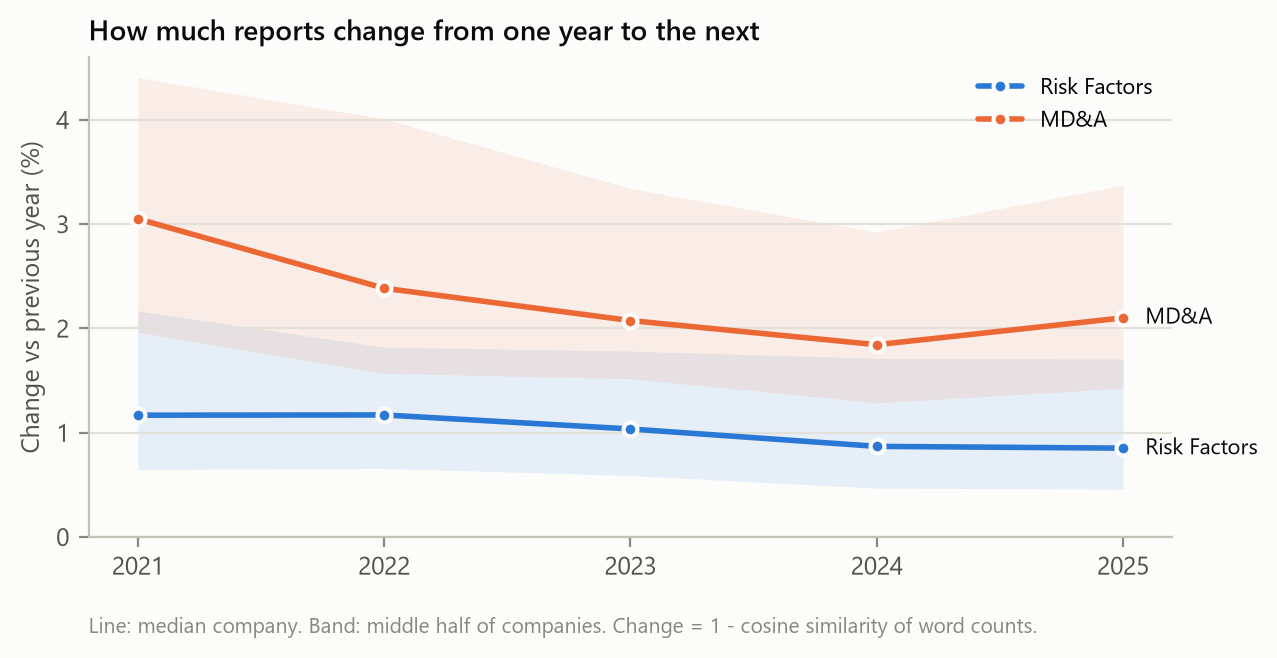

count               25%               50%               75%             
section      MD&A Risk Factors MD&A Risk Factors MD&A Risk Factors MD&A Risk Factors
fiscal_year                                                                         
2021         86.0         93.0  2.0          0.6  3.1          1.2  4.4          2.2
2022         87.0         94.0  1.6          0.7  2.4          1.2  4.0          1.8
2023         87.0         94.0  1.5          0.6  2.1          1.0  3.3          1.8
2024         87.0         94.0  1.3          0.5  1.8          0.9  2.9          1.7
2025         87.0         94.0  1.4          0.5  2.1          0.9  3.4          1.7

In [7]:
text_change = con.execute("SELECT * FROM text_change").df()
fig = plots.change_by_year_chart(text_change, "change_cosine", IMAGES / "04_change_by_year.png")
display(Image(IMAGES / "04_change_by_year.png", width=650))
plots.plt.close(fig)

# The same numbers as a table: median change in % (and the middle half of companies)
q = text_change.assign(section=text_change["item"].map(plots.ITEM_NAMES), pct=text_change["change_cosine"] * 100)
q.groupby(["section", "fiscal_year"])["pct"].describe()[["count", "25%", "50%", "75%"]].round(1).unstack(0)

## 3. The main test: Risk Factors change vs. the next 6 months' return

**Abnormal return** = the stock's return minus the S&P 500's (SPY) over exactly the same days, starting the first trading day **after** the filing date (so an investor could really have read the report). It removes what moved all stocks together.

### 3a. Correlation
Do the change score and the later return move together? The hypothesis says **negative**: more change, lower return. Pearson measures a straight-line relation and can be driven by a few extreme returns; Spearman uses ranks only.

The p-value answers: *if there were no relation at all, how often would a correlation at least this strong appear by chance in a sample this size?* Below 0.05 is the usual (arbitrary) line for "unlikely to be chance".

In [8]:
analysis.correlations(df, [X], analysis.HORIZONS)

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,rf_change_cosine,abnormal_3m,469,0.044,0.341,0.069,0.138
1,rf_change_cosine,abnormal_6m,469,-0.013,0.785,0.022,0.637
2,rf_change_cosine,abnormal_12m,383,-0.009,0.853,-0.016,0.756


### 3b. Groups, as in the paper
Each year, the reports are sorted into five equal groups (quintiles) by how much their Risk Factors changed: group 1 changed least, group 5 most. If the hypothesis holds, bars should fall from left to right. The lines are 95% confidence intervals: the range where the true group average plausibly lies.

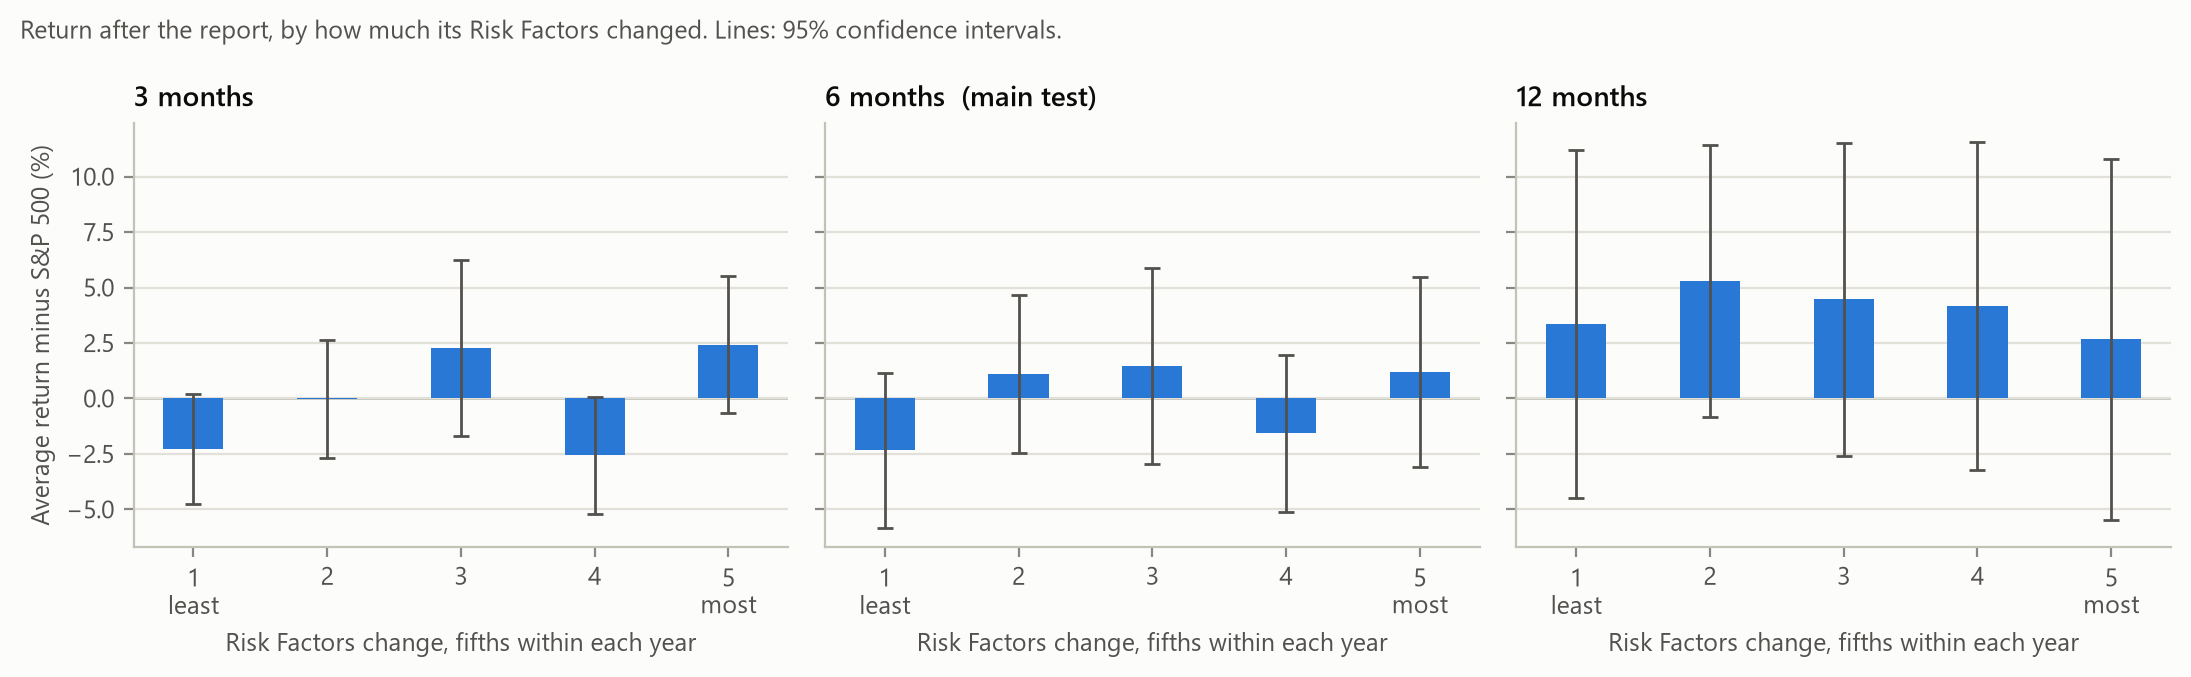

3 months             6 months             12 months            
             n  mean  ci95        n  mean  ci95         n  mean  ci95
group                                                                
1           90 -2.29  2.48       90 -2.34  3.50        73  3.35  7.85
2           95 -0.01  2.66       95  1.09  3.56        78  5.29  6.14
3           94  2.27  3.98       94  1.45  4.42        76  4.47  7.05
4           95 -2.56  2.64       95 -1.58  3.56        78  4.17  7.38
5           95  2.41  3.09       95  1.19  4.29        78  2.67  8.14

In [9]:
groups = {h: analysis.group_returns(df, X, h) for h in analysis.HORIZONS}
fig = plots.group_returns_chart(groups, Y, IMAGES / "04_returns_by_change_group.png")
display(Image(IMAGES / "04_returns_by_change_group.png", width=950))
plots.plt.close(fig)

table = pd.concat({plots.HORIZON_NAMES[h]: g.set_index("group")[["n", "mean", "ci95"]] * [1, 100, 100]
                   for h, g in groups.items()}, axis=1)
table.round(2)  # mean and ci95 in % (return minus S&P 500)

**High minus low:** the most-changed fifth's average return minus the least-changed fifth's. Lazy Prices found a negative difference. Welch's t-test asks whether the difference could be chance (it doesn't assume both groups have the same spread).

In [10]:
hml = pd.DataFrame([analysis.high_minus_low(df, X, h) for h in analysis.HORIZONS])
hml[["mean_high", "mean_low", "difference"]] *= 100  # in %
hml.round(3)

,x,y,n_high,n_low,mean_high,mean_low,difference,t,p_value
0,rf_change_cosine,abnormal_3m,95,90,2.414,-2.286,4.700,2.326,0.021
1,rf_change_cosine,abnormal_6m,95,90,1.186,-2.337,3.522,1.246,0.214
2,rf_change_cosine,abnormal_12m,78,73,2.673,3.349,-0.676,-0.117,0.907


### 3c. Regression: holding other things fixed
Change might just stand in for something else. Companies with bad news may both rewrite their risks *and* have falling stock prices already. So the regression adds:

- **Year and sector effects:** each year and each sector gets its own baseline (a tech-heavy year doesn't count as evidence).
- **Momentum:** the abnormal return over the 12 months *before* the filing.
- **Tone:** FinBERT's tone of the MD&A.
- **Size:** log of total assets.

All inputs are standardized (mean 0, standard deviation 1), so each coefficient reads: *"one standard deviation more of this goes with a return this many percentage points higher (or lower)."* Standard errors are **clustered by company**, because one company's results in different years aren't independent observations; treating them as independent would make the results look more certain than they are.

Three versions, from simple to full, show whether the controls change the answer.

In [11]:
specs = {
    "year effects only":           dict(controls=[], fixed_effects=("fiscal_year",)),
    "year + sector effects":       dict(controls=[], fixed_effects=("fiscal_year", "sector")),
    "+ tone, momentum, size (full)": dict(),
}
fits = {name: analysis.regression(df, X, Y, **spec) for name, spec in specs.items()}
pd.DataFrame({name: analysis.coefficient(fit, X) for name, fit in fits.items()}).T

,coef_pp,std_err,p_value,ci_low,ci_high,n,r2
year effects only,-0.332,0.559,0.553,-1.429,0.764,469.0,0.022
year + sector effects,-0.794,0.590,0.178,-1.951,0.362,469.0,0.071
"+ tone, momentum, size (full)",-0.647,0.658,0.325,-1.936,0.642,430.0,0.094


In [12]:
# Every variable in the full model (coefficients in percentage points per 1 standard deviation)
full = fits["+ tone, momentum, size (full)"]
pd.DataFrame({name: analysis.coefficient(full, name) for name in [X, *analysis.CONTROLS]}).T[
    ["coef_pp", "std_err", "p_value", "ci_low", "ci_high"]]

,coef_pp,std_err,p_value,ci_low,ci_high
rf_change_cosine,-0.647,0.658,0.325,-1.936,0.642
tone,-2.532,0.916,0.006,-4.327,-0.737
past_abnormal_12m,1.598,1.105,0.148,-0.567,3.764
log_assets,-0.784,1.023,0.443,-2.790,1.221


### 3d. Sensitivity: without the two artefacts
The main test, as specified, uses every report. As a check, the same full regression without WMB 2024 and DE 2023 (section 2), whose "change" came from a new report format and a brand name. A result that depends on two artefacts isn't one to trust.

(Deere has no MD&A tone score, so DE 2023 isn't in the full regression anyway: the difference below comes from leaving out **one** report, Williams 2024.)

In [13]:
artefacts = (df["ticker"].eq("WMB") & df["fiscal_year"].eq(2024)) | (df["ticker"].eq("DE") & df["fiscal_year"].eq(2023))
display(df.loc[artefacts, ["ticker", "fiscal_year", X, Y]])
without = analysis.regression(df[~artefacts], X, Y)
pd.DataFrame({"all reports (main test)": analysis.coefficient(full, X),
              "without WMB 2024 and DE 2023": analysis.coefficient(without, X)}).T

,ticker,fiscal_year,rf_change_cosine,abnormal_6m
122,DE,2023,0.302,-0.158
457,WMB,2024,0.353,-0.066


,coef_pp,std_err,p_value,ci_low,ci_high,n,r2
all reports (main test),-0.647,0.658,0.325,-1.936,0.642,430.0,0.094
without WMB 2024 and DE 2023,-0.231,0.825,0.780,-1.848,1.387,429.0,0.094


## 4. Robustness: every measure, every horizon

The same full regression for all 3 measures × 2 sections × 3 horizons = 18 tests. The main test is one of them, chosen in advance. The others show whether the main result is typical or a lucky cell.

**Multiple testing:** with 18 tests at the 5% level, about one would look "significant" even if nothing were going on. The Holm correction (`p_holm`) adjusts each p-value for the number of tests; a result that survives it is much harder to dismiss as luck.

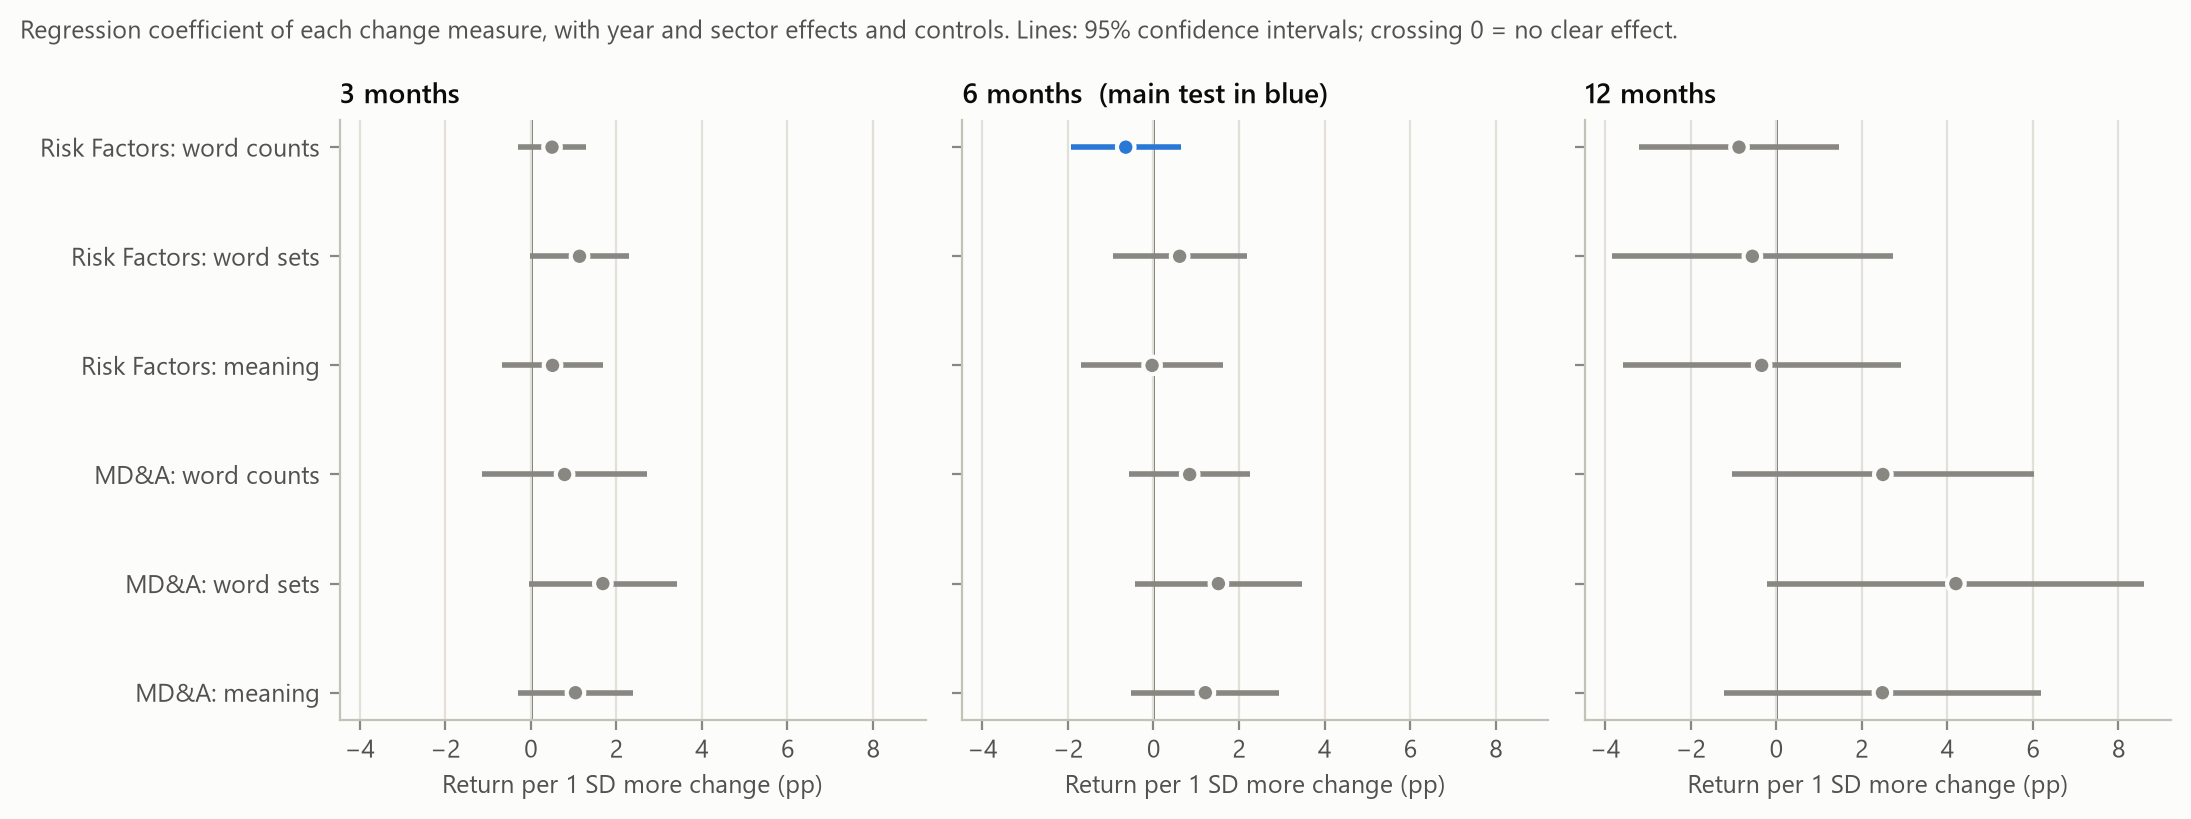

,x,y,primary,n,coef_pp,ci_low,ci_high,p_value,p_holm
0,Risk Factors: word counts,3 months,False,430,0.498,-0.302,1.298,0.222,1.000
1,Risk Factors: word counts,6 months,True,430,-0.647,-1.936,0.642,0.325,1.000
2,Risk Factors: word counts,12 months,False,352,-0.867,-3.205,1.471,0.467,1.000
3,Risk Factors: word sets,3 months,False,430,1.141,-0.026,2.308,0.055,0.989
4,Risk Factors: word sets,6 months,False,430,0.613,-0.954,2.180,0.443,1.000
5,Risk Factors: word sets,12 months,False,352,-0.555,-3.843,2.734,0.741,1.000
6,Risk Factors: meaning,3 months,False,430,0.510,-0.672,1.693,0.398,1.000
7,Risk Factors: meaning,6 months,False,430,-0.031,-1.690,1.628,0.971,1.000
8,Risk Factors: meaning,12 months,False,352,-0.338,-3.587,2.912,0.839,1.000
9,MD&A: word counts,3 months,False,429,0.792,-1.141,2.724,0.422,1.000


In [14]:
grid = analysis.robustness_grid(df)
grid["p_holm"] = multipletests(grid["p_value"], method="holm")[1]
fig = plots.robustness_chart(grid, IMAGES / "04_robustness.png")
display(Image(IMAGES / "04_robustness.png", width=950))
plots.plt.close(fig)
grid.assign(x=grid["x"].map(plots.MEASURE_NAMES), y=grid["y"].map(plots.HORIZON_NAMES))[
    ["x", "y", "primary", "n", "coef_pp", "ci_low", "ci_high", "p_value", "p_holm"]].round(3)

## 5. Tone of the MD&A (FinBERT)

FinBERT rates each MD&A sentence positive, negative or neutral. Tone = average P(positive) − P(negative) over the sentences: −1 all negative, +1 all positive, around 0 for the mostly neutral language of a 10-K. Does the tone follow the economy, and does it say anything about later returns?

In [15]:
tone = con.execute("SELECT * FROM tone").df()
tone.groupby("fiscal_year").agg(reports=("tone", "size"), median_tone=("tone", "median"),
                                negative_share=("negative_share", "median"),
                                positive_share=("positive_share", "median")).round(3)

,reports,median_tone,negative_share,positive_share
fiscal_year,,,,
2020,86,0.005,0.169,0.183
2021,87,0.058,0.141,0.211
2022,87,0.052,0.150,0.202
2023,87,0.059,0.152,0.203
2024,87,0.055,0.143,0.197
2025,87,0.063,0.137,0.214


In [16]:
print("Lowest MD&A tone:")
display(tone.nsmallest(5, "tone")[["ticker", "fiscal_year", "tone", "negative_share", "n_sentences"]])
analysis.correlations(df, ["tone", "tone_change"], analysis.HORIZONS)

Lowest MD&A tone:


,ticker,fiscal_year,tone,negative_share,n_sentences
431,TJX,2020,-0.213,0.364,363
96,CAT,2020,-0.183,0.327,633
72,BA,2020,-0.148,0.347,695
84,BKNG,2020,-0.135,0.308,562
3,AAPL,2023,-0.135,0.259,85


,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,tone,abnormal_3m,435,-0.097,0.043,-0.140,0.003
1,tone,abnormal_6m,435,-0.119,0.013,-0.114,0.017
2,tone,abnormal_12m,356,-0.115,0.030,-0.097,0.067
3,tone_change,abnormal_3m,434,0.075,0.118,0.046,0.337
4,tone_change,abnormal_6m,434,0.043,0.369,0.047,0.324
5,tone_change,abnormal_12m,355,0.025,0.644,0.102,0.054


Tone is only a control in the regression, but it came out with a clear **negative** coefficient there (section 3c): a more positive MD&A went with a *lower* return over the next 6 months. This was not a test chosen in advance, so it is an observation to test on new data, not a finding. A first check: is it one unusual year, or the same sign every year?

In [17]:
from scipy import stats

rows = []
for year, g in df.dropna(subset=["tone", Y]).groupby("fiscal_year"):
    rho = stats.spearmanr(g["tone"], g[Y])
    rows.append({"fiscal_year": year, "n": len(g), "spearman_rho": rho.statistic, "p_value": rho.pvalue})
pd.DataFrame(rows).set_index("fiscal_year").round(3)

,n,spearman_rho,p_value
fiscal_year,,,
2021,87,-0.036,0.742
2022,87,-0.076,0.484
2023,87,-0.097,0.372
2024,87,-0.305,0.004
2025,87,-0.105,0.331


## 6. Topic trends: what do annual reports talk about?

Mentions of a few topics per 10,000 words of the whole report, by fiscal year (the patterns are in `filinglens/research/topics.py`). This measures **attention**, not importance: a report listing "artificial intelligence" among generic risks counts the same as one about its AI products.

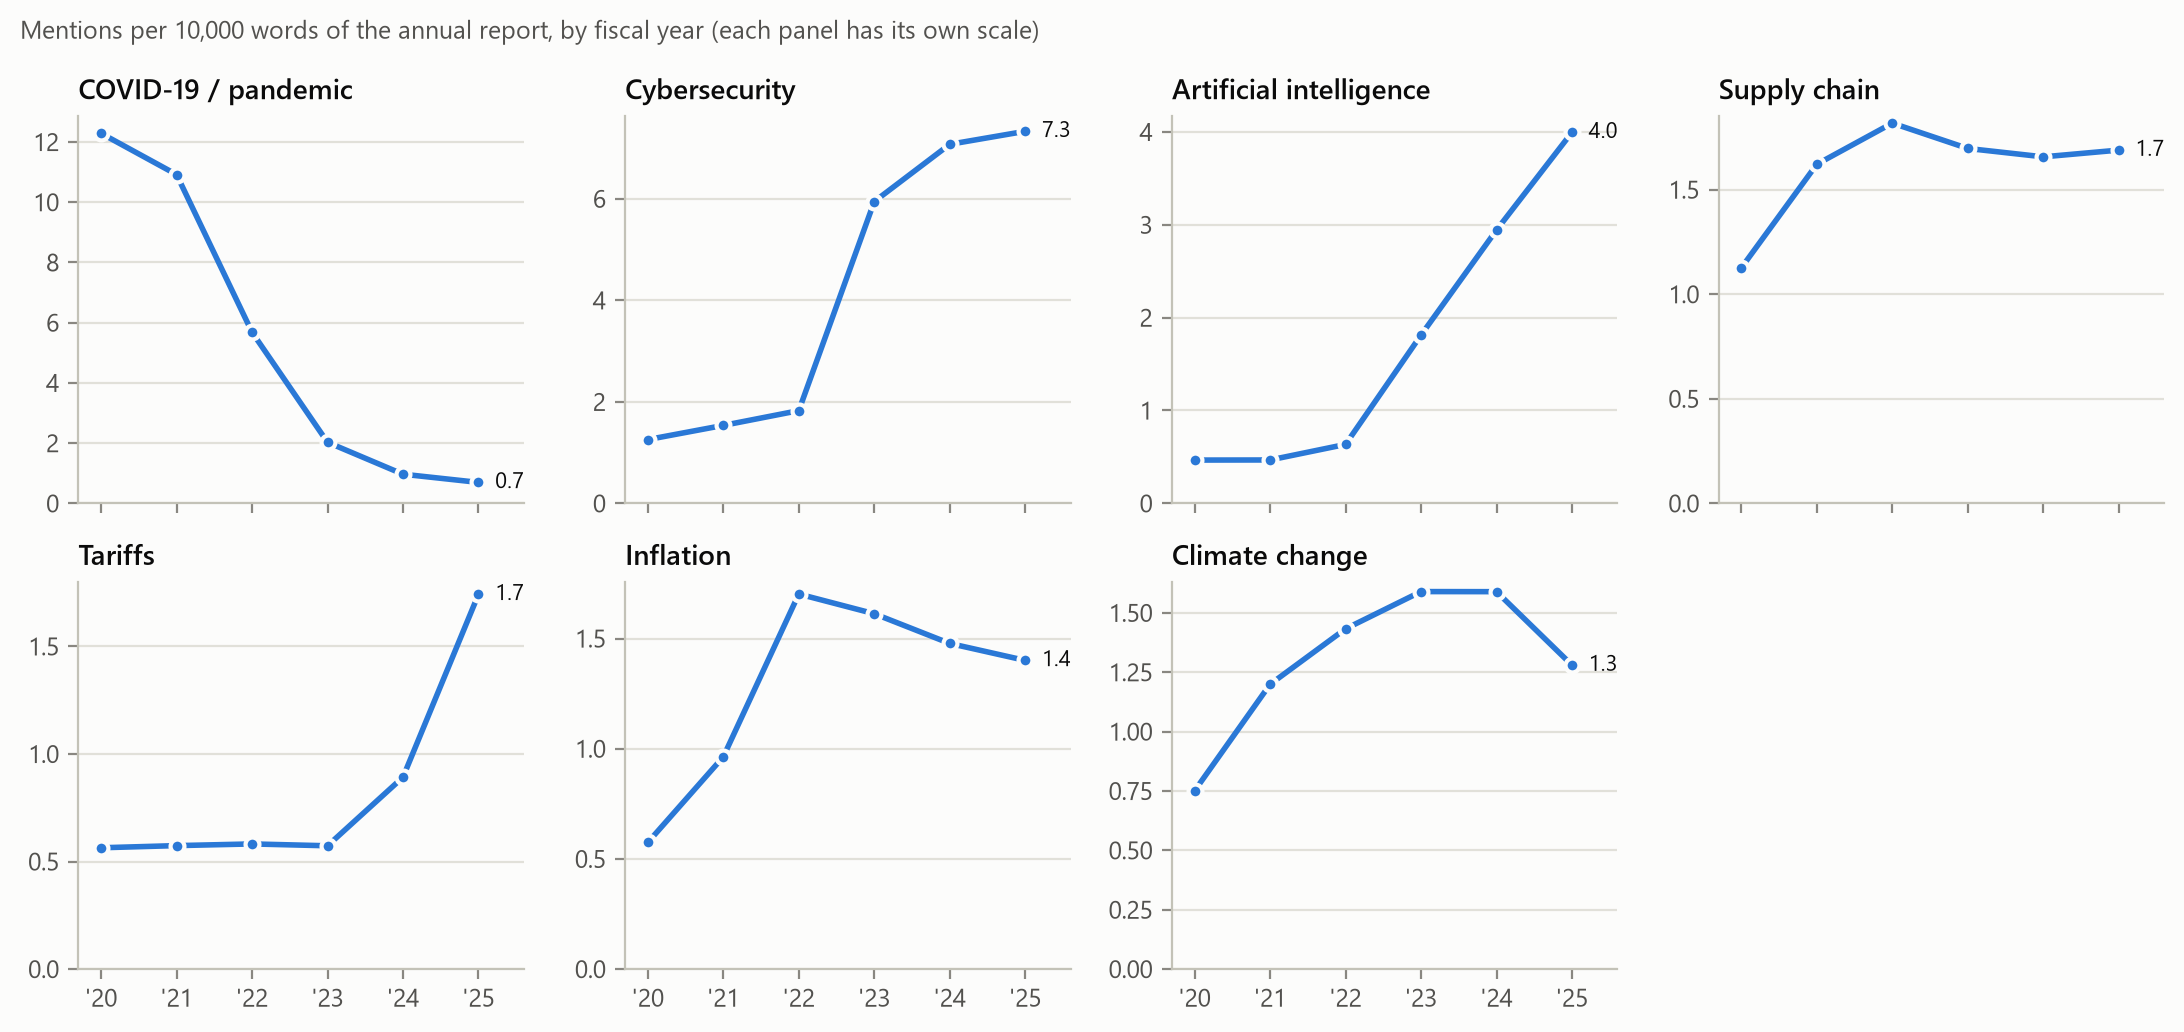

Share of reports mentioning each topic at least once (%):


fiscal_year,2020,2021,2022,2023,2024,2025
topic,,,,,,
Artificial intelligence,24.0,26.0,27.0,67.0,89.0,98.0
COVID-19 / pandemic,100.0,100.0,100.0,97.0,95.0,91.0
Climate change,83.0,95.0,97.0,97.0,98.0,95.0
Cybersecurity,94.0,97.0,98.0,100.0,100.0,100.0
Inflation,81.0,92.0,99.0,98.0,98.0,98.0
Supply chain,86.0,96.0,97.0,95.0,95.0,94.0
Tariffs,85.0,87.0,87.0,86.0,90.0,96.0


In [18]:
trends = topic_trends(con.execute("SELECT * FROM topic_mentions").df())
fig = plots.topic_trends_chart(trends, IMAGES / "04_topic_trends.png")
display(Image(IMAGES / "04_topic_trends.png", width=950))
plots.plt.close(fig)

print("Share of reports mentioning each topic at least once (%):")
(trends.pivot(index="topic", columns="fiscal_year", values="share_mentioning") * 100).round(0)

**Reading it:** artificial intelligence went from a niche word (mentioned in about a quarter of reports for fiscal 2020–22) to nearly every report by fiscal 2025. Cybersecurity jumps in fiscal 2023, when a new SEC rule made every 10-K include a cybersecurity section (Item 1C) for fiscal years ending on or after 15 December 2023: a reminder that text measures react to rules, not only to the world. Tariffs rise in 2024–25; COVID fades but is still mentioned, mostly as history.

## 7. A pitfall you can see in the data: survivorship bias

The 99 companies were picked because they are among the largest in their sector **today**. Companies become the largest by having done well, so the sample is full of past winners. If that matters, the sample's average return will beat the market.

The main test compares companies with each other *within* the same year, so a sample-wide tilt mostly cancels out, but it limits what the results say about companies in general (small, struggling or since-delisted companies are missing entirely).

In [19]:
horizons = ["abnormal_6m", "abnormal_12m"]
by_year = df.groupby("fiscal_year")[horizons].agg(["count", "mean", "median"])
overall = df[horizons].agg(["count", "mean", "median"]).unstack().to_frame("all years").T
table = pd.concat([by_year, overall])
table.loc[:, (slice(None), ["mean", "median"])] *= 100
table.round(2)  # return minus S&P 500, in %; fiscal 2025 has few complete 12-month windows yet

abnormal_6m              abnormal_12m              
                count  mean median        count   mean median
2021             93.0  4.74   4.32         93.0   7.92   5.77
2022             94.0 -2.79  -5.10         94.0  -2.46  -9.22
2023             94.0  0.94   1.13         94.0   4.71  -1.54
2024             94.0 -0.00  -1.97         94.0   7.10   2.97
2025             94.0 -2.92  -5.55          8.0 -10.66 -19.03
all years       469.0 -0.02  -1.66        383.0   4.00   0.79

**Reading it:** the *average* company beat the S&P 500 by about 4 points over 12 months, but the *median* company lagged it in fiscal 2022 and 2023: a few big winners pull the average up. Two biases push in opposite directions here. Survivorship (picking today's winners) pushes our sample up. But the S&P 500 weights companies by size, and in 2023–24 a handful of giant tech stocks drove most of its gains, which our equal-weighted sample of 99 companies (9 per sector) couldn't match. "Abnormal return" is always relative to a benchmark, and the choice of benchmark matters.

## 8. Summary

The key numbers for `docs/04_research_findings.md`.

In [20]:
corr = analysis.correlations(df, [X], [Y]).iloc[0]
diff = analysis.high_minus_low(df, X, Y)
main = analysis.coefficient(full, X)
primary_row = grid[grid["primary"]].iloc[0]
print(f"Sample: {len(df)} company-years, {df['ticker'].nunique()} companies; {int(df[Y].notna().sum())} with a 6-month return")
print(f"Spearman correlation, Risk Factors change vs 6-month abnormal return: "
      f"{corr['spearman_rho']:+.3f} (p = {corr['spearman_p']:.3f})")
print(f"Most-changed fifth minus least-changed fifth: {diff['difference'] * 100:+.2f} pp (p = {diff['p_value']:.3f})")
print(f"Regression (full): {main['coef_pp']:+.2f} pp per 1 SD more change, "
      f"95% CI [{main['ci_low']:+.2f}, {main['ci_high']:+.2f}], p = {main['p_value']:.3f}, n = {main['n']}")
print(f"After the Holm correction for 18 tests: p = {primary_row['p_holm']:.3f}")
w = analysis.coefficient(without, X)
print(f"Without the two artefacts (WMB 2024, DE 2023): {w['coef_pp']:+.2f} pp, "
      f"95% CI [{w['ci_low']:+.2f}, {w['ci_high']:+.2f}], p = {w['p_value']:.3f}")
t = analysis.coefficient(full, "tone")
print(f"Exploratory: MD&A tone in the full model: {t['coef_pp']:+.2f} pp per 1 SD more positive, p = {t['p_value']:.3f}")
print(f"Tests with p < 0.05 out of {len(grid)}: {(grid['p_value'] < 0.05).sum()} "
      f"({(grid['p_holm'] < 0.05).sum()} after the Holm correction)")

Sample: 469 company-years, 94 companies; 469 with a 6-month return
Spearman correlation, Risk Factors change vs 6-month abnormal return: +0.022 (p = 0.637)
Most-changed fifth minus least-changed fifth: +3.52 pp (p = 0.214)
Regression (full): -0.65 pp per 1 SD more change, 95% CI [-1.94, +0.64], p = 0.325, n = 430
After the Holm correction for 18 tests: p = 1.000
Without the two artefacts (WMB 2024, DE 2023): -0.23 pp, 95% CI [-1.85, +1.39], p = 0.780
Exploratory: MD&A tone in the full model: -2.53 pp per 1 SD more positive, p = 0.006
Tests with p < 0.05 out of 18: 0 (0 after the Holm correction)


In [21]:
con.close()